Sample=3883, Order=515, n_normal=1281, n_malig=61
  Mann-Whitney: U=37823.0, p=6.7326e-01
  Welch t-test: t=-0.7527, p=4.5440e-01


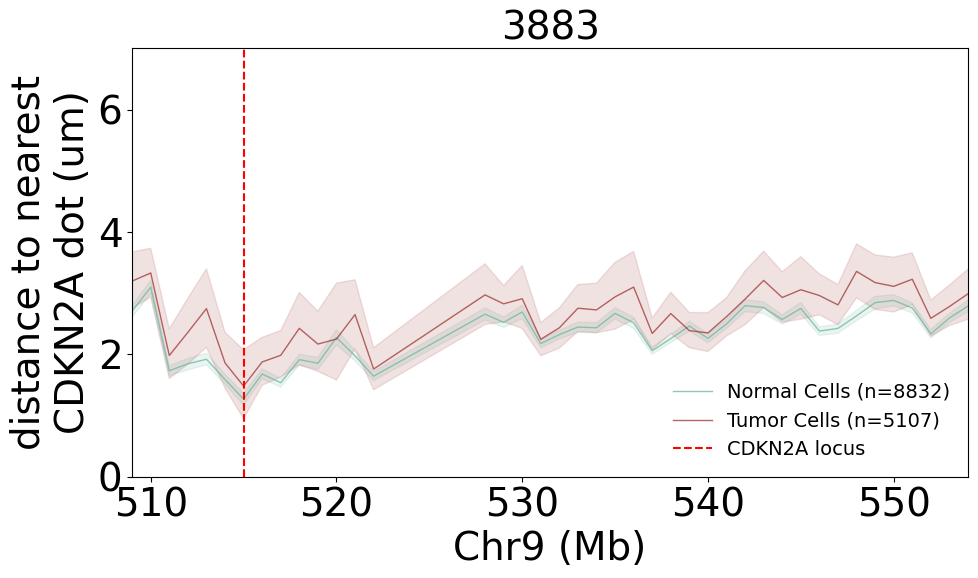

In [1]:
import numpy as np
import pandas as pd
import os
import pickle
import matplotlib.pyplot as plt
import matplotlib
from scipy.stats import mannwhitneyu, ttest_ind

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
#matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size'] = 14

JOB_ID = 4
sample_list = ['2543', '2683', '5121', '5597', '3883']
JOB_SAMPLE = sample_list[JOB_ID]

targets = ['CDKN2A']

palette_hex = [
    "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
    "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
    "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
    "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
    "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
    "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
    "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
    "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
    "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
    "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
    "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
    "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
    "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
    "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
    "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
]

N_BOOT = 1000
ALPHA = 0.05

NORMAL_TYPES = ['Microglia', 'Pericytes', 'Neuron GABA.', 'Neuron Glut.',
                'Olig. normal', 'Endothelial', 'T', 'AC']
MALIG_TYPES = ['AC.like', 'OPC.like Prolif.', 'OPC']

LEGEND_LABELS = {
    'normal': 'Normal Cells',
    'malig': 'Tumor Cells',
}


def bootstrap_ci(values, n_boot=1000, alpha=0.05):
    """Return mean, lower, and upper CI using bootstrap."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    boot_means = [
        np.mean(np.random.choice(values, size=len(values), replace=True))
        for _ in range(n_boot)
    ]
    lower = np.percentile(boot_means, 100 * alpha / 2)
    upper = np.percentile(boot_means, 100 * (1 - alpha / 2))
    return np.mean(values), lower, upper


for target in targets:

    with open(f'{target}_distance_{JOB_SAMPLE}.pickle', 'rb') as f:
        data = pickle.load(f)
    with open(f'celltypes_for{target}_{JOB_SAMPLE}.pickle', 'rb') as f:
        celltypes = pickle.load(f)

    dna_loci = pd.read_csv(
        '/resnick/groups/CaiLab/jjfox/copied_from_central/gbm_dna_analysis/'
        '25-07-28_combined_dna/human_1k_genomic_loci_final.csv'
    )
    dna_loci['block_num'] = dna_loci['bin_name'].str.extract(r'block(\d+)_').astype(int)
    dna_loci['bin_num'] = dna_loci['bin_name'].str.extract(r'bin(\d+)').astype(int)
    dna_loci['order'] = ((dna_loci['block_num'] - 1) * 15) + dna_loci['bin_num']

    change_points = dna_loci.loc[
        dna_loci['bin_chromosome'] != dna_loci['bin_chromosome'].shift(),
        ['bin_chromosome', 'order']
    ].reset_index(drop=True)

    groups = {
        'normal': np.where(np.isin(celltypes, NORMAL_TYPES))[0],
        'malig':  np.where(np.isin(celltypes, MALIG_TYPES))[0],
    }
    colors = {
        'normal': palette_hex[0],
        'malig':  palette_hex[1],
    }

    fig, ax = plt.subplots(figsize=(10, 6))

    order_val = 515
    group_values_at_order = {}

    for label, positions in groups.items():
        x_all, y_all = [], []
        for idx in positions:
            x_lists, y_lists = data[idx]
            x_all.extend(x_lists)
            y_all.extend(y_lists)

        all_x = sorted(set(np.concatenate(x_all)))
        y_matrix = np.full((len(y_all), len(all_x)), np.nan)
        for k, (xs, ys) in enumerate(zip(x_all, y_all)):
            xs, ys = np.asarray(xs), np.asarray(ys)
            for j, x_val in enumerate(all_x):
                match = np.where(xs == x_val)[0]
                if len(match) > 0:
                    y_matrix[k, j] = ys[match[0]]

        mean_y, lower_y, upper_y = [], [], []
        for j in range(len(all_x)):
            m, lo, hi = bootstrap_ci(y_matrix[:, j], N_BOOT, ALPHA)
            mean_y.append(m)
            lower_y.append(lo)
            upper_y.append(hi)

        mean_y = np.array(mean_y)
        lower_y = np.array(lower_y)
        upper_y = np.array(upper_y)

        ax.plot(all_x, mean_y, color=colors[label], lw=1, alpha=0.8,
                label=f'{LEGEND_LABELS[label]} (n={len(y_all)})')
        ax.fill_between(all_x, lower_y, upper_y, color=colors[label], alpha=0.15)

        if order_val in all_x:
            j_idx = all_x.index(order_val)
            col = y_matrix[:, j_idx]
            col = col[np.isfinite(col)]
            group_values_at_order[label] = col
            
    ax.axvline(x=515, color='red', linestyle='--', lw=1.5, label='CDKN2A locus')
    
    if 'normal' in group_values_at_order and 'malig' in group_values_at_order:
        n_vals = group_values_at_order['normal']
        m_vals = group_values_at_order['malig']

        mw_stat, mw_pval = mannwhitneyu(n_vals, m_vals, alternative='two-sided')
        t_stat, t_pval = ttest_ind(n_vals, m_vals, equal_var=False)  # Welch's t-test

        print(f"Sample={JOB_SAMPLE}, Order={order_val}, "
              f"n_normal={len(n_vals)}, n_malig={len(m_vals)}")
        print(f"  Mann-Whitney: U={mw_stat:.1f}, p={mw_pval:.4e}")
        print(f"  Welch t-test: t={t_stat:.4f}, p={t_pval:.4e}")

    ax.set_xlabel('Chr9 (Mb)', fontsize=28)
    ax.set_ylabel(f'distance to nearest\n{target} dot (um)', fontsize=28)
    ax.set_title(JOB_SAMPLE, fontsize=28)
    ax.tick_params(axis='both', labelsize=28)
    ax.set_ylim(0, 7)
    ax.set_xlim(509, 554)
    ax.legend(loc='lower right', frameon=False)
    fig.tight_layout()

    plt.show()
    #save_path = (f'../../../figures/Figure_2/Figure_2C/'
    #             f'edit_chr9_{JOB_SAMPLE}_normalvsmalignant_{target}_proximity_trace.png')
    #os.makedirs(os.path.dirname(save_path), exist_ok=True)
    #fig.savefig(save_path, dpi=300, bbox_inches='tight')
    #plt.close(fig)

In [ ]:
df = pd.read_csv('/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/CNV_mat.csv')

df.columns = df.columns.str.replace('.', '_', regex=False)

In [4]:
df

,ID,block1_bin1,block1_bin2,block1_bin3,block1_bin4,block1_bin5,block1_bin6,block1_bin7,block1_bin8,block1_bin9,...,block67_bin14,block67_bin15,block68_bin1,block68_bin2,block68_bin3,block68_bin4,block68_bin5,patient,type_1,type_2
0,19AF747,0.067114,0.052573,0.014680,0.024447,0.024132,0.000576,-0.010873,0.052027,0.062470,...,-0.050689,-0.107195,-0.007916,-0.085911,-0.947878,-0.594128,-0.465802,p3,Grade I,Ganglio
1,2122,-0.761198,-0.762483,-0.756655,-0.720697,-0.749831,-0.757721,-0.762400,-0.778317,-0.822918,...,-0.129116,-0.116351,-0.166515,-0.232566,-0.255148,-0.180287,-0.290301,p8,LGG_MT,Oligo
2,2543,-0.469452,-0.398087,-0.382937,-0.361469,-0.362918,-0.334790,-0.384714,-0.391569,-0.397868,...,-0.064183,-0.018472,-0.019839,-0.002877,0.020890,0.055922,0.015518,p9,Transformed,Oligo
3,2683,-0.104337,-0.068562,-0.060447,-0.055621,-0.048073,-0.046750,-0.097322,-0.138209,-0.098272,...,-0.021531,0.034603,0.132430,0.152129,0.188555,0.165181,0.314195,p22,LGG_MT,Astro
4,2789,0.004254,0.053683,0.062947,0.063943,0.101116,0.099994,0.072421,0.071894,0.078687,...,0.065413,0.124444,0.137103,0.048344,0.042930,0.031728,0.003898,p14,LGG_MT,Astro
5,2830,-0.166083,-0.167508,-0.136777,-0.080976,-0.094762,-0.069207,-0.077325,-0.075368,-0.118143,...,0.001142,-0.078232,0.041088,0.046906,-0.024593,-0.088625,0.057836,p13,LGG_MT,Astro
6,3097_1,-0.024906,0.001823,0.003361,0.043341,0.029169,0.035693,-0.020852,-0.033217,-0.113435,...,-0.378597,-0.365301,-0.149346,-0.210697,-0.153723,-0.028283,-0.177712,p23,GBM,GBM
7,3209,0.059518,0.056188,0.064856,0.104586,0.115599,0.129413,0.131322,0.124636,0.085845,...,-0.023327,-0.194315,-0.158218,-0.061510,-0.211619,-0.507665,-0.196867,p42,LGG_MT,Astro
8,3364,-0.475470,-0.496261,-0.519110,-0.505492,-0.528441,-0.566193,-0.558557,-0.533289,-0.530524,...,0.001438,0.116597,0.243172,0.284029,0.199415,0.196034,0.168333,p16,LGG_noMT,Oligo
9,3557,-0.814645,-0.811470,-0.818037,-0.807034,-0.815965,-0.834173,-0.852889,-0.859880,-0.885381,...,0.056409,0.136983,0.114815,0.111577,0.143103,0.141166,0.034626,p4,LGG_MT,Oligo


In [5]:
bin_to_order = dict(zip(dna_loci['bin_name'],dna_loci['order']))

In [6]:
df.rename(columns=bin_to_order, inplace=True)

In [7]:
df.head()

,ID,1,2,3,4,5,6,7,8,9,...,1004,1005,1006,1007,1008,1009,1010,patient,type_1,type_2
0,19AF747,0.067114,0.052573,0.014680,0.024447,0.024132,0.000576,-0.010873,0.052027,0.062470,...,-0.050689,-0.107195,-0.007916,-0.085911,-0.947878,-0.594128,-0.465802,p3,Grade I,Ganglio
1,2122,-0.761198,-0.762483,-0.756655,-0.720697,-0.749831,-0.757721,-0.762400,-0.778317,-0.822918,...,-0.129116,-0.116351,-0.166515,-0.232566,-0.255148,-0.180287,-0.290301,p8,LGG_MT,Oligo
2,2543,-0.469452,-0.398087,-0.382937,-0.361469,-0.362918,-0.334790,-0.384714,-0.391569,-0.397868,...,-0.064183,-0.018472,-0.019839,-0.002877,0.020890,0.055922,0.015518,p9,Transformed,Oligo
3,2683,-0.104337,-0.068562,-0.060447,-0.055621,-0.048073,-0.046750,-0.097322,-0.138209,-0.098272,...,-0.021531,0.034603,0.132430,0.152129,0.188555,0.165181,0.314195,p22,LGG_MT,Astro
4,2789,0.004254,0.053683,0.062947,0.063943,0.101116,0.099994,0.072421,0.071894,0.078687,...,0.065413,0.124444,0.137103,0.048344,0.042930,0.031728,0.003898,p14,LGG_MT,Astro


In [28]:
sample_cnv = df.loc[df['ID'] == '5121']

In [29]:
cnvs = sample_cnv.iloc[0].loc[509:555]

In [30]:
cnvs

509   -0.015544
510   -0.220246
511   -1.105581
512   -1.194738
513   -1.524964
514   -1.427931
515   -1.399533
516   -1.479424
517   -1.194991
518   -0.922243
519   -0.389876
520   -0.253499
521   -0.149812
522    0.015648
528    0.039673
529      0.2072
530    0.218884
531     0.19674
532    0.180919
533    0.163519
534    0.126471
535    0.160967
536    0.272231
537    0.297566
538    0.310738
539    0.294198
540    0.296839
541    0.165604
542    0.051565
543   -0.382774
544   -0.203678
545   -0.217393
546   -0.231632
547   -0.211176
548    -0.15536
549   -0.269216
550   -0.195414
551   -0.022486
552   -0.015661
553    0.002838
554    0.078316
555    0.097731
Name: 16, dtype: object

In [31]:
type(cnvs)

pandas.core.series.Series

Sample=5121, Order=515, n_normal=415, n_malig=112
  Mann-Whitney: U=9511.5, p=8.0333e-22
  Welch t-test: t=-9.8208, p=1.3113e-17


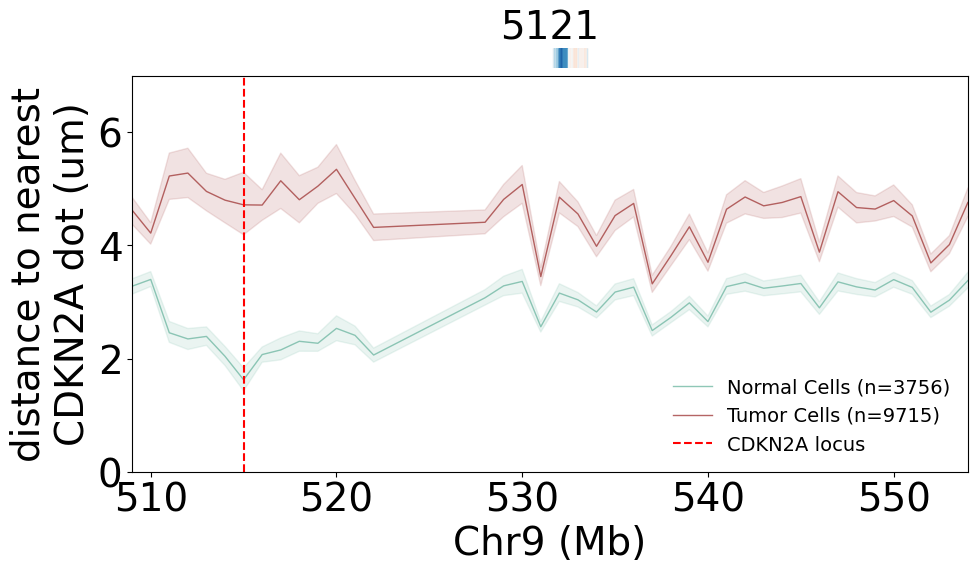

In [27]:
import numpy as np
import pandas as pd
import os
import pickle
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from scipy.stats import mannwhitneyu, ttest_ind

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
#matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size'] = 14

JOB_ID = 2
sample_list = ['2543', '2683', '5121', '5597', '3883']
JOB_SAMPLE = sample_list[JOB_ID]

targets = ['CDKN2A']

palette_hex = [
    "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
    "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
    "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
    "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
    "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
    "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
    "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
    "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
    "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
    "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
    "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
    "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
    "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
    "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
    "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
]

N_BOOT = 1000
ALPHA = 0.05

NORMAL_TYPES = ['Microglia', 'Pericytes', 'Neuron GABA.', 'Neuron Glut.',
                'Olig. normal', 'Endothelial', 'T', 'AC']
MALIG_TYPES = ['AC.like', 'OPC.like Prolif.', 'OPC']

LEGEND_LABELS = {
    'normal': 'Normal Cells',
    'malig': 'Tumor Cells',
}


def bootstrap_ci(values, n_boot=1000, alpha=0.05):
    """Return mean, lower, and upper CI using bootstrap."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    boot_means = [
        np.mean(np.random.choice(values, size=len(values), replace=True))
        for _ in range(n_boot)
    ]
    lower = np.percentile(boot_means, 100 * alpha / 2)
    upper = np.percentile(boot_means, 100 * (1 - alpha / 2))
    return np.mean(values), lower, upper


for target in targets:

    with open(f'{target}_distance_{JOB_SAMPLE}.pickle', 'rb') as f:
        data = pickle.load(f)
    with open(f'celltypes_for{target}_{JOB_SAMPLE}.pickle', 'rb') as f:
        celltypes = pickle.load(f)

    dna_loci = pd.read_csv(
        '/resnick/groups/CaiLab/jjfox/copied_from_central/gbm_dna_analysis/'
        '25-07-28_combined_dna/human_1k_genomic_loci_final.csv'
    )
    dna_loci['block_num'] = dna_loci['bin_name'].str.extract(r'block(\d+)_').astype(int)
    dna_loci['bin_num'] = dna_loci['bin_name'].str.extract(r'bin(\d+)').astype(int)
    dna_loci['order'] = ((dna_loci['block_num'] - 1) * 15) + dna_loci['bin_num']

    change_points = dna_loci.loc[
        dna_loci['bin_chromosome'] != dna_loci['bin_chromosome'].shift(),
        ['bin_chromosome', 'order']
    ].reset_index(drop=True)

    groups = {
        'normal': np.where(np.isin(celltypes, NORMAL_TYPES))[0],
        'malig':  np.where(np.isin(celltypes, MALIG_TYPES))[0],
    }
    colors = {
        'normal': palette_hex[0],
        'malig':  palette_hex[1],
    }

    fig, ax = plt.subplots(figsize=(10, 6))

    order_val = 515
    group_values_at_order = {}

    for label, positions in groups.items():
        x_all, y_all = [], []
        for idx in positions:
            x_lists, y_lists = data[idx]
            x_all.extend(x_lists)
            y_all.extend(y_lists)

        all_x = sorted(set(np.concatenate(x_all)))
        y_matrix = np.full((len(y_all), len(all_x)), np.nan)
        for k, (xs, ys) in enumerate(zip(x_all, y_all)):
            xs, ys = np.asarray(xs), np.asarray(ys)
            for j, x_val in enumerate(all_x):
                match = np.where(xs == x_val)[0]
                if len(match) > 0:
                    y_matrix[k, j] = ys[match[0]]

        mean_y, lower_y, upper_y = [], [], []
        for j in range(len(all_x)):
            m, lo, hi = bootstrap_ci(y_matrix[:, j], N_BOOT, ALPHA)
            mean_y.append(m)
            lower_y.append(lo)
            upper_y.append(hi)

        mean_y = np.array(mean_y)
        lower_y = np.array(lower_y)
        upper_y = np.array(upper_y)

        ax.plot(all_x, mean_y, color=colors[label], lw=1, alpha=0.8,
                label=f'{LEGEND_LABELS[label]} (n={len(y_all)})')
        ax.fill_between(all_x, lower_y, upper_y, color=colors[label], alpha=0.15)

        if order_val in all_x:
            j_idx = all_x.index(order_val)
            col = y_matrix[:, j_idx]
            col = col[np.isfinite(col)]
            group_values_at_order[label] = col
            
    ax.axvline(x=515, color='red', linestyle='--', lw=1.5, label='CDKN2A locus')
    
    if 'normal' in group_values_at_order and 'malig' in group_values_at_order:
        n_vals = group_values_at_order['normal']
        m_vals = group_values_at_order['malig']

        mw_stat, mw_pval = mannwhitneyu(n_vals, m_vals, alternative='two-sided')
        t_stat, t_pval = ttest_ind(n_vals, m_vals, equal_var=False)  # Welch's t-test

        print(f"Sample={JOB_SAMPLE}, Order={order_val}, "
              f"n_normal={len(n_vals)}, n_malig={len(m_vals)}")
        print(f"  Mann-Whitney: U={mw_stat:.1f}, p={mw_pval:.4e}")
        print(f"  Welch t-test: t={t_stat:.4f}, p={t_pval:.4e}")

    # colorbar at top of plot
    divider_y = 0.95  # fraction of axes height for the bar
    bar_height = 0.03  # fraction of axes height
    
    # build colormap: blue -> white -> red
    cmap = cm.RdBu_r
    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    
    # create an inset axes at the top
    cbar_ax = ax.inset_axes([0, 1.02, 1, 0.05])  # [left, bottom, width, height] in axes fraction
    
    # plot each segment of the colorbar
    x_vals = cnvs.index.values
    colors_mapped = cmap(norm(cnvs.values.astype(float)))
    
    for i in range(len(x_vals) - 1):
        cbar_ax.axvspan(x_vals[i], x_vals[i + 1], color=colors_mapped[i])
    
    cbar_ax.set_xlim(ax.get_xlim())
    cbar_ax.set_yticks([])
    cbar_ax.set_xticks([])
    cbar_ax.spines[:].set_visible(False)
    
    ax.set_xlabel('Chr9 (Mb)', fontsize=28)
    ax.set_ylabel(f'distance to nearest\n{target} dot (um)', fontsize=28)
    ax.set_title(JOB_SAMPLE, fontsize=28)
    ax.tick_params(axis='both', labelsize=28)
    ax.set_ylim(0, 7)
    ax.set_xlim(509, 554)
    ax.legend(loc='lower right', frameon=False)
    fig.tight_layout()

    plt.show()
    #save_path = (f'../../../figures/Figure_2/Figure_2C/'
    #             f'edit_chr9_{JOB_SAMPLE}_normalvsmalignant_{target}_proximity_trace.png')
    #os.makedirs(os.path.dirname(save_path), exist_ok=True)
    #fig.savefig(save_path, dpi=300, bbox_inches='tight')
    #plt.close(fig)

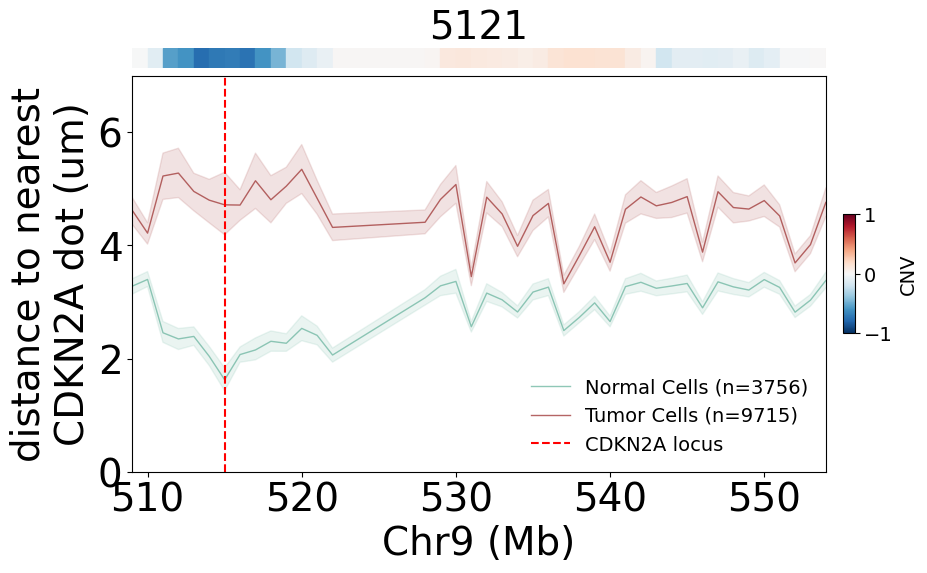

In [34]:
cmap = cm.RdBu_r
norm = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)

cbar_ax = ax.inset_axes([0, 1.02, 1, 0.05])

x_vals = cnvs.index.values.astype(float)
colors_mapped = cmap(norm(cnvs.values.astype(float)))

for i in range(len(x_vals) - 1):
    cbar_ax.axvspan(x_vals[i], x_vals[i + 1], color=colors_mapped[i])

cbar_ax.set_xlim(ax.get_xlim())
cbar_ax.set_yticks([])
cbar_ax.set_xticks([])
cbar_ax.spines[:].set_visible(False)

fig

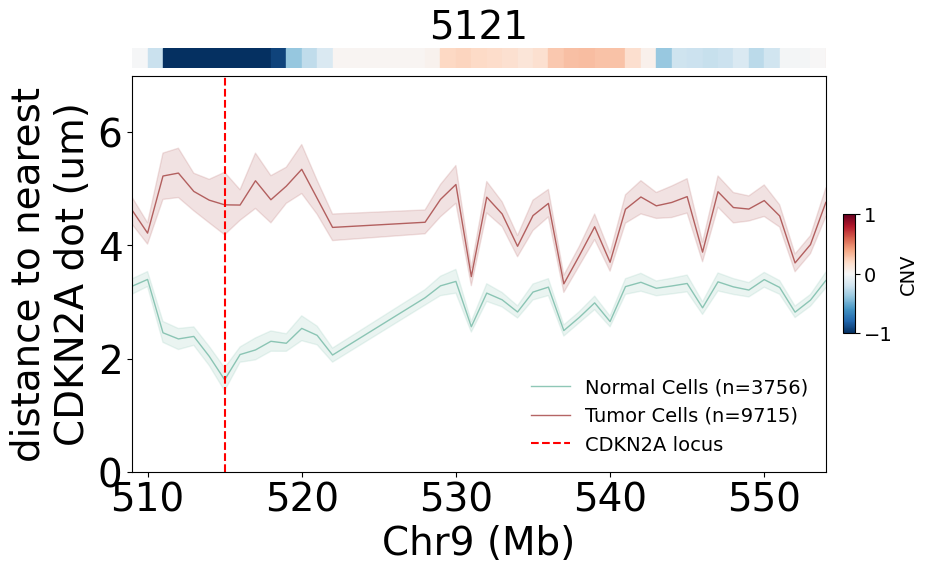

In [33]:
import matplotlib.colorbar as cbar_mod

# create a ScalarMappable for the legend colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# add a colorbar axis to the right of the main plot
cbar = fig.colorbar(sm, ax=ax, location='right', shrink=0.3, pad=0.02, aspect=10)
cbar.set_ticks([-1, 0, 1])
cbar.set_label('CNV', fontsize=14)

fig

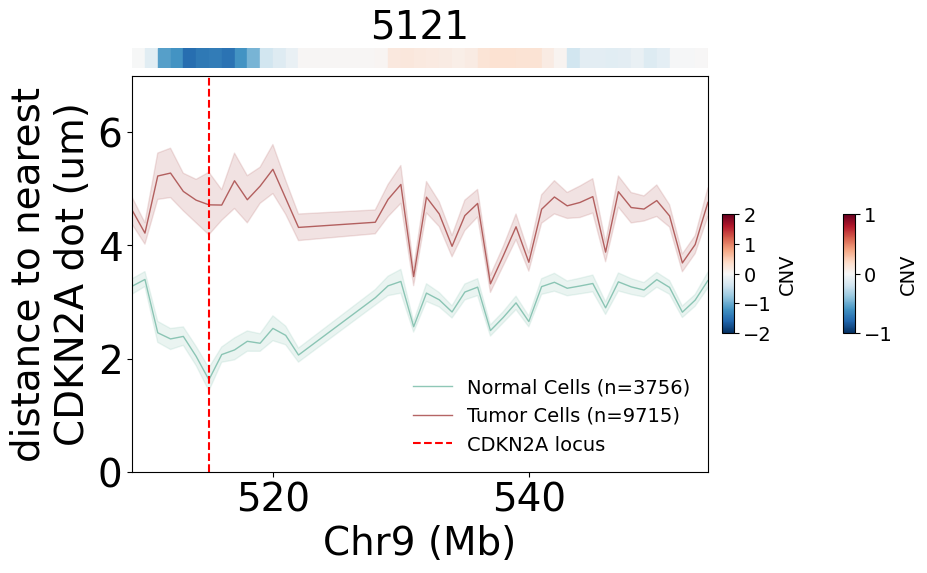

In [35]:
norm = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)

# redo the inset bar colors
cbar_ax.clear()
colors_mapped = cmap(norm(cnvs.values.astype(float)))
x_vals = cnvs.index.values.astype(float)
for i in range(len(x_vals) - 1):
    cbar_ax.axvspan(x_vals[i], x_vals[i + 1], color=colors_mapped[i])
cbar_ax.set_xlim(ax.get_xlim())
cbar_ax.set_yticks([])
cbar_ax.set_xticks([])
cbar_ax.spines[:].set_visible(False)

# redo the side colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
# remove old colorbar if it exists
if hasattr(fig, '_last_cbar'):
    fig._last_cbar.remove()
cbar = fig.colorbar(sm, ax=ax, location='right', shrink=0.3, pad=0.02, aspect=10)
cbar.set_ticks([-2, -1, 0, 1, 2])
cbar.set_label('CNV', fontsize=14)
fig._last_cbar = cbar

fig

Sample=5121, Order=515, n_normal=415, n_malig=112
  Mann-Whitney: U=9511.5, p=8.0333e-22
  Welch t-test: t=-9.8208, p=1.3113e-17


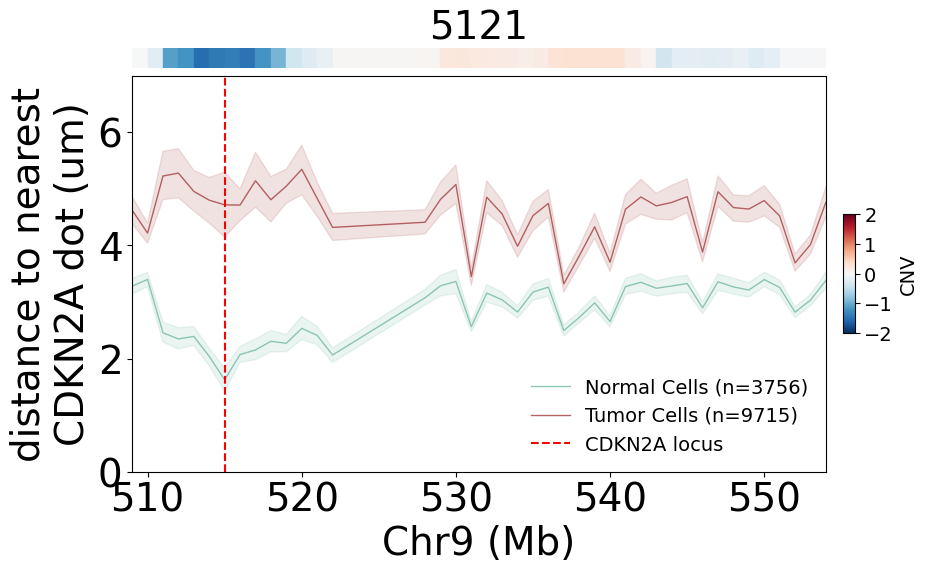

In [41]:
import numpy as np
import pandas as pd
import os
import pickle
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from scipy.stats import mannwhitneyu, ttest_ind

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['font.size'] = 14

JOB_ID = 2
sample_list = ['2543', '2683', '5121', '5597', '3883']
JOB_SAMPLE = sample_list[JOB_ID]

targets = ['CDKN2A']

palette_hex = [
    "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
    "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
    "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
    "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
    "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
    "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
    "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
    "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
    "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
    "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
    "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
    "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
    "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
    "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
    "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
]

# get CNV profile for chromosome
sample_cnv = df.loc[df['ID'] == JOB_SAMPLE]
cnvs = sample_cnv.iloc[0].loc[509:555]


N_BOOT = 1000
ALPHA = 0.05

NORMAL_TYPES = ['Microglia', 'Pericytes', 'Neuron GABA.', 'Neuron Glut.',
                'Olig. normal', 'Endothelial', 'T', 'AC']
MALIG_TYPES = ['AC.like', 'OPC.like Prolif.', 'OPC']

LEGEND_LABELS = {
    'normal': 'Normal Cells',
    'malig': 'Tumor Cells',
}


def bootstrap_ci(values, n_boot=1000, alpha=0.05):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    boot_means = [
        np.mean(np.random.choice(values, size=len(values), replace=True))
        for _ in range(n_boot)
    ]
    lower = np.percentile(boot_means, 100 * alpha / 2)
    upper = np.percentile(boot_means, 100 * (1 - alpha / 2))
    return np.mean(values), lower, upper


for target in targets:

    with open(f'{target}_distance_{JOB_SAMPLE}.pickle', 'rb') as f:
        data = pickle.load(f)
    with open(f'celltypes_for{target}_{JOB_SAMPLE}.pickle', 'rb') as f:
        celltypes = pickle.load(f)

    dna_loci = pd.read_csv(
        '/resnick/groups/CaiLab/jjfox/copied_from_central/gbm_dna_analysis/'
        '25-07-28_combined_dna/human_1k_genomic_loci_final.csv'
    )
    dna_loci['block_num'] = dna_loci['bin_name'].str.extract(r'block(\d+)_').astype(int)
    dna_loci['bin_num'] = dna_loci['bin_name'].str.extract(r'bin(\d+)').astype(int)
    dna_loci['order'] = ((dna_loci['block_num'] - 1) * 15) + dna_loci['bin_num']

    change_points = dna_loci.loc[
        dna_loci['bin_chromosome'] != dna_loci['bin_chromosome'].shift(),
        ['bin_chromosome', 'order']
    ].reset_index(drop=True)

    groups = {
        'normal': np.where(np.isin(celltypes, NORMAL_TYPES))[0],
        'malig':  np.where(np.isin(celltypes, MALIG_TYPES))[0],
    }
    colors = {
        'normal': palette_hex[0],
        'malig':  palette_hex[1],
    }

    fig, ax = plt.subplots(figsize=(10, 6))

    order_val = 515
    group_values_at_order = {}

    for label, positions in groups.items():
        x_all, y_all = [], []
        for idx in positions:
            x_lists, y_lists = data[idx]
            x_all.extend(x_lists)
            y_all.extend(y_lists)

        all_x = sorted(set(np.concatenate(x_all)))
        y_matrix = np.full((len(y_all), len(all_x)), np.nan)
        for k, (xs, ys) in enumerate(zip(x_all, y_all)):
            xs, ys = np.asarray(xs), np.asarray(ys)
            for j, x_val in enumerate(all_x):
                match = np.where(xs == x_val)[0]
                if len(match) > 0:
                    y_matrix[k, j] = ys[match[0]]

        mean_y, lower_y, upper_y = [], [], []
        for j in range(len(all_x)):
            m, lo, hi = bootstrap_ci(y_matrix[:, j], N_BOOT, ALPHA)
            mean_y.append(m)
            lower_y.append(lo)
            upper_y.append(hi)

        mean_y = np.array(mean_y)
        lower_y = np.array(lower_y)
        upper_y = np.array(upper_y)

        ax.plot(all_x, mean_y, color=colors[label], lw=1, alpha=0.8,
                label=f'{LEGEND_LABELS[label]} (n={len(y_all)})')
        ax.fill_between(all_x, lower_y, upper_y, color=colors[label], alpha=0.15)

        if order_val in all_x:
            j_idx = all_x.index(order_val)
            col = y_matrix[:, j_idx]
            col = col[np.isfinite(col)]
            group_values_at_order[label] = col

    ax.axvline(x=515, color='red', linestyle='--', lw=1.5, label='CDKN2A locus')

    if 'normal' in group_values_at_order and 'malig' in group_values_at_order:
        n_vals = group_values_at_order['normal']
        m_vals = group_values_at_order['malig']

        mw_stat, mw_pval = mannwhitneyu(n_vals, m_vals, alternative='two-sided')
        t_stat, t_pval = ttest_ind(n_vals, m_vals, equal_var=False)

        print(f"Sample={JOB_SAMPLE}, Order={order_val}, "
              f"n_normal={len(n_vals)}, n_malig={len(m_vals)}")
        print(f"  Mann-Whitney: U={mw_stat:.1f}, p={mw_pval:.4e}")
        print(f"  Welch t-test: t={t_stat:.4f}, p={t_pval:.4e}")

    # --- CNV colorbar at top ---
    cmap_cnv = cm.RdBu_r
    norm_cnv = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)

    cbar_ax = ax.inset_axes([0, 1.02, 1, 0.05])
    x_vals = cnvs.index.values.astype(float)
    colors_mapped = cmap_cnv(norm_cnv(cnvs.values.astype(float)))

    for i in range(len(x_vals) - 1):
        cbar_ax.axvspan(x_vals[i], x_vals[i + 1], color=colors_mapped[i])

    cbar_ax.set_xlim(509, 554)
    cbar_ax.set_yticks([])
    cbar_ax.set_xticks([])
    cbar_ax.spines[:].set_visible(False)

    # --- CNV colormap legend on right ---
    sm = cm.ScalarMappable(cmap=cmap_cnv, norm=norm_cnv)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, location='right', shrink=0.3, pad=0.02, aspect=10)
    cbar.set_ticks([-2, -1, 0, 1, 2])
    cbar.set_label('CNV', fontsize=14)

    ax.set_xlabel('Chr9 (Mb)', fontsize=28)
    ax.set_ylabel(f'distance to nearest\n{target} dot (um)', fontsize=28)
    ax.set_title(JOB_SAMPLE, fontsize=28)
    ax.tick_params(axis='both', labelsize=28)
    ax.set_ylim(0, 7)
    ax.set_xlim(509, 554)
    ax.legend(loc='lower right', frameon=False)
    fig.tight_layout()

    plt.show()

Sample=2543, Order=515, n_normal=5506, n_malig=771
  Mann-Whitney: U=2281269.0, p=7.5808e-04
  Welch t-test: t=2.8871, p=3.9694e-03


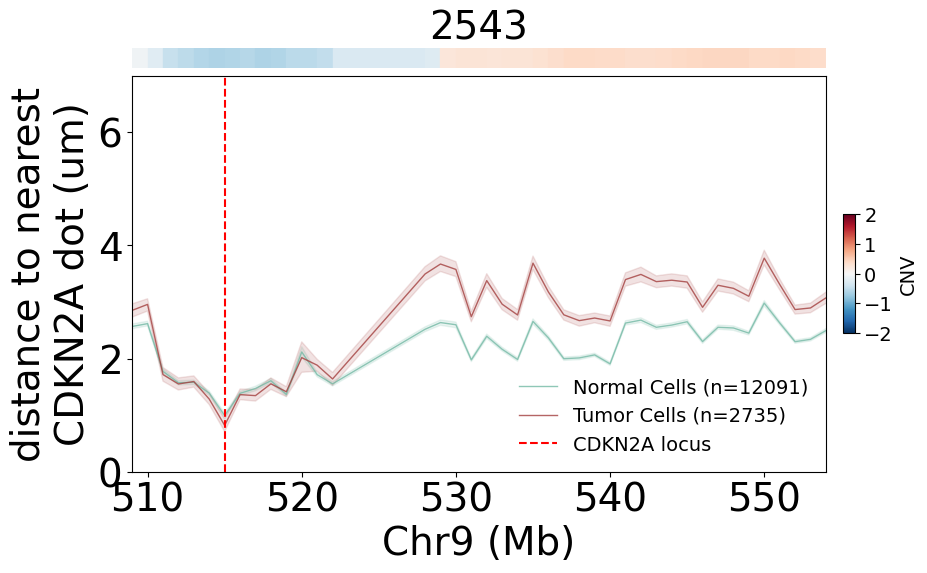

Sample=2683, Order=515, n_normal=604, n_malig=897
  Mann-Whitney: U=273215.0, p=7.7811e-01
  Welch t-test: t=0.7734, p=4.3942e-01


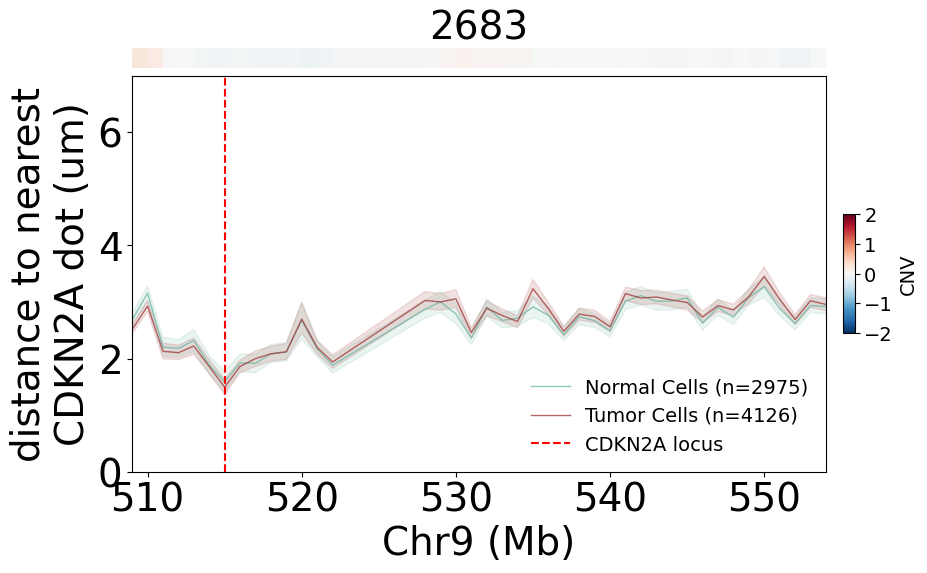

Sample=5597, Order=515, n_normal=73, n_malig=33
  Mann-Whitney: U=866.5, p=2.1290e-02
  Welch t-test: t=-2.3711, p=2.1479e-02


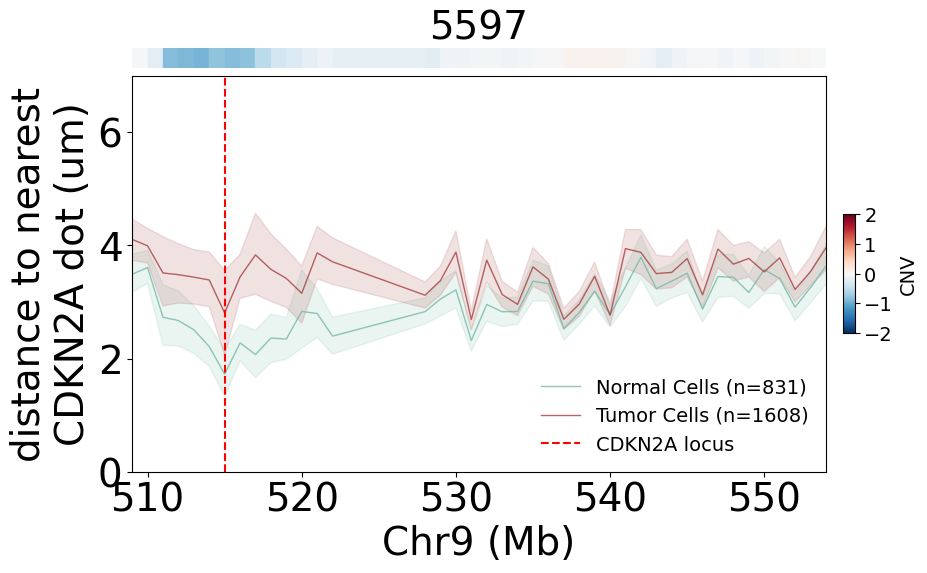

Sample=3883, Order=515, n_normal=1281, n_malig=61
  Mann-Whitney: U=37823.0, p=6.7326e-01
  Welch t-test: t=-0.7527, p=4.5440e-01


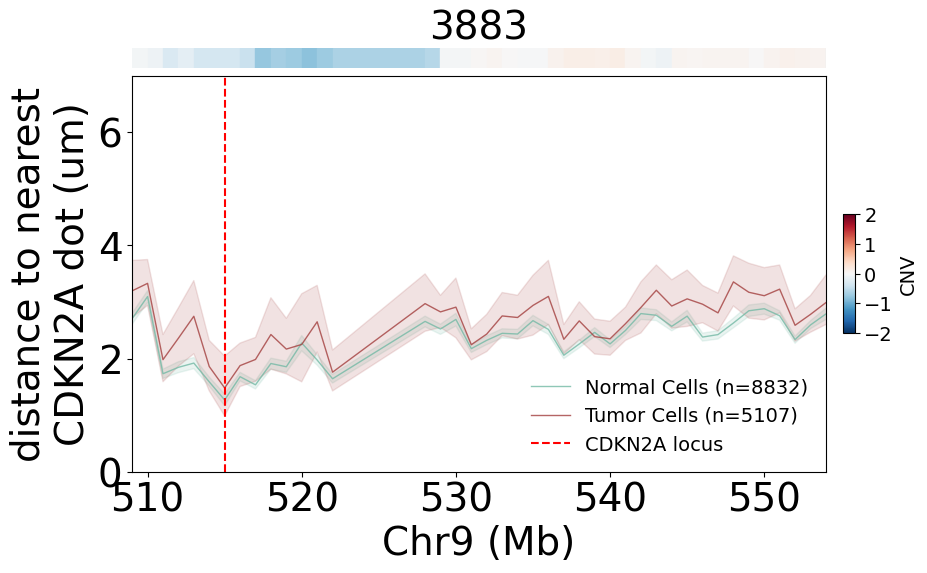

In [42]:


for jid in [0,1,3,4]:
    JOB_ID = jid
    sample_list = ['2543', '2683', '5121', '5597', '3883']
    JOB_SAMPLE = sample_list[JOB_ID]
    
    targets = ['CDKN2A']
    
    palette_hex = [
        "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
        "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
        "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
        "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
        "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
        "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
        "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
        "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
        "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
        "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
        "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
        "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
        "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
        "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
        "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
    ]
    
    # get CNV profile for chromosome
    sample_cnv = df.loc[df['ID'] == JOB_SAMPLE]
    cnvs = sample_cnv.iloc[0].loc[509:555]
    
    
    N_BOOT = 1000
    ALPHA = 0.05
    
    NORMAL_TYPES = ['Microglia', 'Pericytes', 'Neuron GABA.', 'Neuron Glut.',
                    'Olig. normal', 'Endothelial', 'T', 'AC']
    MALIG_TYPES = ['AC.like', 'OPC.like Prolif.', 'OPC']
    
    LEGEND_LABELS = {
        'normal': 'Normal Cells',
        'malig': 'Tumor Cells',
    }
    
    
    def bootstrap_ci(values, n_boot=1000, alpha=0.05):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]
        if len(values) == 0:
            return np.nan, np.nan, np.nan
        boot_means = [
            np.mean(np.random.choice(values, size=len(values), replace=True))
            for _ in range(n_boot)
        ]
        lower = np.percentile(boot_means, 100 * alpha / 2)
        upper = np.percentile(boot_means, 100 * (1 - alpha / 2))
        return np.mean(values), lower, upper
    
    
    for target in targets:
    
        with open(f'{target}_distance_{JOB_SAMPLE}.pickle', 'rb') as f:
            data = pickle.load(f)
        with open(f'celltypes_for{target}_{JOB_SAMPLE}.pickle', 'rb') as f:
            celltypes = pickle.load(f)
    
        dna_loci = pd.read_csv(
            '/resnick/groups/CaiLab/jjfox/copied_from_central/gbm_dna_analysis/'
            '25-07-28_combined_dna/human_1k_genomic_loci_final.csv'
        )
        dna_loci['block_num'] = dna_loci['bin_name'].str.extract(r'block(\d+)_').astype(int)
        dna_loci['bin_num'] = dna_loci['bin_name'].str.extract(r'bin(\d+)').astype(int)
        dna_loci['order'] = ((dna_loci['block_num'] - 1) * 15) + dna_loci['bin_num']
    
        change_points = dna_loci.loc[
            dna_loci['bin_chromosome'] != dna_loci['bin_chromosome'].shift(),
            ['bin_chromosome', 'order']
        ].reset_index(drop=True)
    
        groups = {
            'normal': np.where(np.isin(celltypes, NORMAL_TYPES))[0],
            'malig':  np.where(np.isin(celltypes, MALIG_TYPES))[0],
        }
        colors = {
            'normal': palette_hex[0],
            'malig':  palette_hex[1],
        }
    
        fig, ax = plt.subplots(figsize=(10, 6))
    
        order_val = 515
        group_values_at_order = {}
    
        for label, positions in groups.items():
            x_all, y_all = [], []
            for idx in positions:
                x_lists, y_lists = data[idx]
                x_all.extend(x_lists)
                y_all.extend(y_lists)
    
            all_x = sorted(set(np.concatenate(x_all)))
            y_matrix = np.full((len(y_all), len(all_x)), np.nan)
            for k, (xs, ys) in enumerate(zip(x_all, y_all)):
                xs, ys = np.asarray(xs), np.asarray(ys)
                for j, x_val in enumerate(all_x):
                    match = np.where(xs == x_val)[0]
                    if len(match) > 0:
                        y_matrix[k, j] = ys[match[0]]
    
            mean_y, lower_y, upper_y = [], [], []
            for j in range(len(all_x)):
                m, lo, hi = bootstrap_ci(y_matrix[:, j], N_BOOT, ALPHA)
                mean_y.append(m)
                lower_y.append(lo)
                upper_y.append(hi)
    
            mean_y = np.array(mean_y)
            lower_y = np.array(lower_y)
            upper_y = np.array(upper_y)
    
            ax.plot(all_x, mean_y, color=colors[label], lw=1, alpha=0.8,
                    label=f'{LEGEND_LABELS[label]} (n={len(y_all)})')
            ax.fill_between(all_x, lower_y, upper_y, color=colors[label], alpha=0.15)
    
            if order_val in all_x:
                j_idx = all_x.index(order_val)
                col = y_matrix[:, j_idx]
                col = col[np.isfinite(col)]
                group_values_at_order[label] = col
    
        ax.axvline(x=515, color='red', linestyle='--', lw=1.5, label='CDKN2A locus')
    
        if 'normal' in group_values_at_order and 'malig' in group_values_at_order:
            n_vals = group_values_at_order['normal']
            m_vals = group_values_at_order['malig']
    
            mw_stat, mw_pval = mannwhitneyu(n_vals, m_vals, alternative='two-sided')
            t_stat, t_pval = ttest_ind(n_vals, m_vals, equal_var=False)
    
            print(f"Sample={JOB_SAMPLE}, Order={order_val}, "
                  f"n_normal={len(n_vals)}, n_malig={len(m_vals)}")
            print(f"  Mann-Whitney: U={mw_stat:.1f}, p={mw_pval:.4e}")
            print(f"  Welch t-test: t={t_stat:.4f}, p={t_pval:.4e}")
    
        # --- CNV colorbar at top ---
        cmap_cnv = cm.RdBu_r
        norm_cnv = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)
    
        cbar_ax = ax.inset_axes([0, 1.02, 1, 0.05])
        x_vals = cnvs.index.values.astype(float)
        colors_mapped = cmap_cnv(norm_cnv(cnvs.values.astype(float)))
    
        for i in range(len(x_vals) - 1):
            cbar_ax.axvspan(x_vals[i], x_vals[i + 1], color=colors_mapped[i])
    
        cbar_ax.set_xlim(509, 554)
        cbar_ax.set_yticks([])
        cbar_ax.set_xticks([])
        cbar_ax.spines[:].set_visible(False)
    
        # --- CNV colormap legend on right ---
        sm = cm.ScalarMappable(cmap=cmap_cnv, norm=norm_cnv)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, location='right', shrink=0.3, pad=0.02, aspect=10)
        cbar.set_ticks([-2, -1, 0, 1, 2])
        cbar.set_label('CNV', fontsize=14)
    
        ax.set_xlabel('Chr9 (Mb)', fontsize=28)
        ax.set_ylabel(f'distance to nearest\n{target} dot (um)', fontsize=28)
        ax.set_title(JOB_SAMPLE, fontsize=28)
        ax.tick_params(axis='both', labelsize=28)
        ax.set_ylim(0, 7)
        ax.set_xlim(509, 554)
        ax.legend(loc='lower right', frameon=False)
        fig.tight_layout()
    
        plt.show()

In [45]:


for jid in [0,1,2,3,4,5]:
    JOB_ID = jid
    sample_list = ['3557', '4590', '2122' , '4904', '4555', '2830' ]
    JOB_SAMPLE = sample_list[JOB_ID]
    
    targets = ['CDKN2A']
    
    palette_hex = [
        "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
        "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
        "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
        "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
        "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
        "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
        "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
        "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
        "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
        "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
        "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
        "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
        "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
        "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
        "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
    ]
    
    # get CNV profile for chromosome
    sample_cnv = df.loc[df['ID'] == JOB_SAMPLE]
    cnvs = sample_cnv.iloc[0].loc[509:555]
    
    
    N_BOOT = 1000
    ALPHA = 0.05
    
    NORMAL_TYPES = ['Microglia', 'Pericytes', 'Neuron GABA.', 'Neuron Glut.',
                    'Olig. normal', 'Endothelial', 'T', 'AC']
    MALIG_TYPES = ['AC.like', 'OPC.like Prolif.', 'OPC']
    
    LEGEND_LABELS = {
        'normal': 'Normal Cells',
        'malig': 'Tumor Cells',
    }
    
    
    def bootstrap_ci(values, n_boot=1000, alpha=0.05):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]
        if len(values) == 0:
            return np.nan, np.nan, np.nan
        boot_means = [
            np.mean(np.random.choice(values, size=len(values), replace=True))
            for _ in range(n_boot)
        ]
        lower = np.percentile(boot_means, 100 * alpha / 2)
        upper = np.percentile(boot_means, 100 * (1 - alpha / 2))
        return np.mean(values), lower, upper
    
    
    for target in targets:
    
        with open(f'{target}_distance_{JOB_SAMPLE}.pickle', 'rb') as f:
            data = pickle.load(f)
        with open(f'celltypes_for{target}_{JOB_SAMPLE}.pickle', 'rb') as f:
            celltypes = pickle.load(f)
    
        dna_loci = pd.read_csv(
            '/resnick/groups/CaiLab/jjfox/copied_from_central/gbm_dna_analysis/'
            '25-07-28_combined_dna/human_1k_genomic_loci_final.csv'
        )
        dna_loci['block_num'] = dna_loci['bin_name'].str.extract(r'block(\d+)_').astype(int)
        dna_loci['bin_num'] = dna_loci['bin_name'].str.extract(r'bin(\d+)').astype(int)
        dna_loci['order'] = ((dna_loci['block_num'] - 1) * 15) + dna_loci['bin_num']
    
        change_points = dna_loci.loc[
            dna_loci['bin_chromosome'] != dna_loci['bin_chromosome'].shift(),
            ['bin_chromosome', 'order']
        ].reset_index(drop=True)
    
        groups = {
            'normal': np.where(np.isin(celltypes, NORMAL_TYPES))[0],
            'malig':  np.where(np.isin(celltypes, MALIG_TYPES))[0],
        }
        colors = {
            'normal': palette_hex[0],
            'malig':  palette_hex[1],
        }
    
        fig, ax = plt.subplots(figsize=(10, 6))
    
        order_val = 515
        group_values_at_order = {}
    
        for label, positions in groups.items():
            x_all, y_all = [], []
            for idx in positions:
                x_lists, y_lists = data[idx]
                x_all.extend(x_lists)
                y_all.extend(y_lists)
    
            all_x = sorted(set(np.concatenate(x_all)))
            y_matrix = np.full((len(y_all), len(all_x)), np.nan)
            for k, (xs, ys) in enumerate(zip(x_all, y_all)):
                xs, ys = np.asarray(xs), np.asarray(ys)
                for j, x_val in enumerate(all_x):
                    match = np.where(xs == x_val)[0]
                    if len(match) > 0:
                        y_matrix[k, j] = ys[match[0]]
    
            mean_y, lower_y, upper_y = [], [], []
            for j in range(len(all_x)):
                m, lo, hi = bootstrap_ci(y_matrix[:, j], N_BOOT, ALPHA)
                mean_y.append(m)
                lower_y.append(lo)
                upper_y.append(hi)
    
            mean_y = np.array(mean_y)
            lower_y = np.array(lower_y)
            upper_y = np.array(upper_y)
    
            ax.plot(all_x, mean_y, color=colors[label], lw=1, alpha=0.8,
                    label=f'{LEGEND_LABELS[label]} (n={len(y_all)})')
            ax.fill_between(all_x, lower_y, upper_y, color=colors[label], alpha=0.15)
    
            if order_val in all_x:
                j_idx = all_x.index(order_val)
                col = y_matrix[:, j_idx]
                col = col[np.isfinite(col)]
                group_values_at_order[label] = col
    
        ax.axvline(x=515, color='red', linestyle='--', lw=1.5, label='CDKN2A locus')
    
        if 'normal' in group_values_at_order and 'malig' in group_values_at_order:
            n_vals = group_values_at_order['normal']
            m_vals = group_values_at_order['malig']
    
            mw_stat, mw_pval = mannwhitneyu(n_vals, m_vals, alternative='two-sided')
            t_stat, t_pval = ttest_ind(n_vals, m_vals, equal_var=False)
    
            print(f"Sample={JOB_SAMPLE}, Order={order_val}, "
                  f"n_normal={len(n_vals)}, n_malig={len(m_vals)}")
            print(f"  Mann-Whitney: U={mw_stat:.1f}, p={mw_pval:.4e}")
            print(f"  Welch t-test: t={t_stat:.4f}, p={t_pval:.4e}")
    
        # --- CNV colorbar at top ---
        cmap_cnv = cm.RdBu_r
        norm_cnv = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)
    
        cbar_ax = ax.inset_axes([0, 1.02, 1, 0.05])
        x_vals = cnvs.index.values.astype(float)
        colors_mapped = cmap_cnv(norm_cnv(cnvs.values.astype(float)))
    
        for i in range(len(x_vals) - 1):
            cbar_ax.axvspan(x_vals[i], x_vals[i + 1], color=colors_mapped[i])
    
        cbar_ax.set_xlim(509, 554)
        cbar_ax.set_yticks([])
        cbar_ax.set_xticks([])
        cbar_ax.spines[:].set_visible(False)
    
        # --- CNV colormap legend on right ---
        sm = cm.ScalarMappable(cmap=cmap_cnv, norm=norm_cnv)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, location='right', shrink=0.3, pad=0.02, aspect=10)
        cbar.set_ticks([-2, -1, 0, 1, 2])
        cbar.set_label('CNV', fontsize=14)
    
        ax.set_xlabel('Chr9 (Mb)', fontsize=28)
        ax.set_ylabel(f'distance to nearest\n{target} dot (um)', fontsize=28)
        ax.set_title(JOB_SAMPLE, fontsize=28)
        ax.tick_params(axis='both', labelsize=28)
        ax.set_ylim(0, 7)
        ax.set_xlim(509, 554)
        ax.legend(loc='lower right', frameon=False)
        fig.tight_layout()
    
        plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'CDKN2A_distance_3557.pickle'